# Data insights

In [ ]:
##### Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, json, folium
from folium.plugins import HeatMap

##### Data path
DATA_PATH = os.path.join(
    os.getcwd(),
    'Data'
)

##### Common variables
MONTHS=[
    'Jan', 'Feb', 'Mar', 'Apr', 'May',
    'Jun', 'Jul', 'Aug', 'Sep', 'Oct'
]


In [25]:
##### Preparing data
df = pd.read_csv(
    f'{DATA_PATH}/food_clean.csv',
    parse_dates=['conversion_date']
)


#### Creating client full names
df['full_name'] = df['first_name'] + "_" + df['last_name']


#### Creating month and hourly variables
df['month'] = df['conversion_date'].dt.month
df['hour'] = df['conversion_date'].dt.hour

#### Summing up individual numbers of populations
population_cols = [col for col in df.columns if col.startswith('number')]
df['number_household_sum'] = df[population_cols[0]] + \
    df[population_cols[1]] + \
    df[population_cols[2]] + \
    df[population_cols[3]]

#### Quantitative and Qualitative Variables
quant_vars = [col for col in df.columns if col.startswith('number')]
qual_vars = list(set(df.columns) - set(quant_vars))


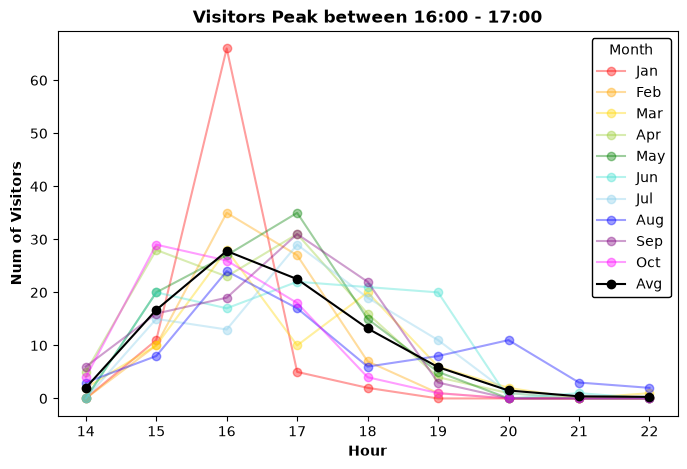

In [ ]:
##### First Name
# * Names:
#     - Seeing consistent clients throughout time (monthly)
#     - Summing over hourly and seeing change of demand per hour

#### Consistent clients
df_consistent_clients = df.groupby(
    by=['first_name','last_name'],
    as_index=False
).agg(
    num_months_visited = pd.NamedAgg(
        column='month',
        aggfunc=lambda series: series.count()
    ),
    household_sum = pd.NamedAgg(
        column='number_household_sum',
        aggfunc=lambda series: series.mean().round(2)
    )
).sort_values(
    by='num_months_visited',
    # by='household_sum',
    ascending=False
)

# display(df_consistent_clients)





#### Change of demand per hour
df_monthly_hour_change = df.groupby(
    by=['month','hour'],
    as_index=False
).agg(
    num_clients = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.count()
    )
).sort_values(
    by=['month','hour'],
    ascending=[True,True]
)

#### Dropping outliers
    # Registrations at the following hours occured 1/2 times:
        # 0,1,11,12,13,23
df_monthly_hour_change = df_monthly_hour_change[
    ~df_monthly_hour_change['hour'].isin([0,1,11,12,13,23])
]

#### Ensuring all months have the same hours
all_months =df_monthly_hour_change['month'].unique()
all_hours = df_monthly_hour_change['hour'].unique()
full_index = pd.MultiIndex.from_product(
    [all_months, all_hours],
    names=['month','hour']
)
df_complete_m_h_change = df_monthly_hour_change\
    .set_index(['month', 'hour'])\
    .reindex(full_index, fill_value=0)\
    .reset_index()\
    .sort_values(
        by=['month','hour'],
        ascending=[True,True]
    )

df_avg_per_hour = df_complete_m_h_change\
    .groupby(
        by='hour',
        as_index=False
    ).agg(
        avg_clients = pd.NamedAgg(
            column='num_clients',
            aggfunc= lambda series: series.mean()
        )
    ).sort_values(
        by='hour',
        ascending=True
    )

# display(df_complete_m_h_change)
# display(df_avg_per_hour)

#### Visualization
ANCH = 8
ALT = 5
fig, ax = plt.subplots(figsize=(ANCH,ALT))
num_unique_hours = np.arange(len(all_hours))
num_unique_months = np.arange(len(all_months))
month_colors = [
    "red",          # Enero
    "orange",       # Febrero
    "gold",         # Marzo
    "yellowgreen",  # Abril
    "green",        # Mayo
    "turquoise",    # Junio
    "skyblue",      # Julio
    "blue",         # Agosto
    "purple",       # Septiembre
    "magenta",      # Octubre
    # "brown",        # Noviembre
    # "gray"          # Diciembre
]
### All months
for month_num in num_unique_months:
    ax.plot(
        num_unique_hours,
        df_complete_m_h_change[
            df_complete_m_h_change['month'] == (month_num + 1)
        ]['num_clients'],
        label = MONTHS[month_num],
        color= month_colors[month_num],
        marker='o',
        alpha=0.38
    )
### Average of clients per hour
ax.plot(
    num_unique_hours,
    df_avg_per_hour["avg_clients"],
    label = 'Avg',
    color = 'black',
    marker='o'
)
### Configs
ax.set_ylabel('Num of Visitors', fontweight='bold')
ax.set_xlabel('Hour', fontweight='bold')
ax.set_xticks(num_unique_hours)
ax.set_xticklabels([str(v) for v in np.sort(all_hours)])
ax.legend(
    title='Month',
    framealpha=1,
    edgecolor='black'
)
ax.set_title(
    'Visitors Peak between 16:00 - 17:00',
    fontweight='bold'    
)
plt.show()



### Insights: Num visitors per hour
* 1600 has the peak number of visitors
* January had a unusually large number of visitors
* Majority of visitors come between 1500 - 1900

##### Recommendation
* Personel re-distribution during high hours of 1500 - 1700

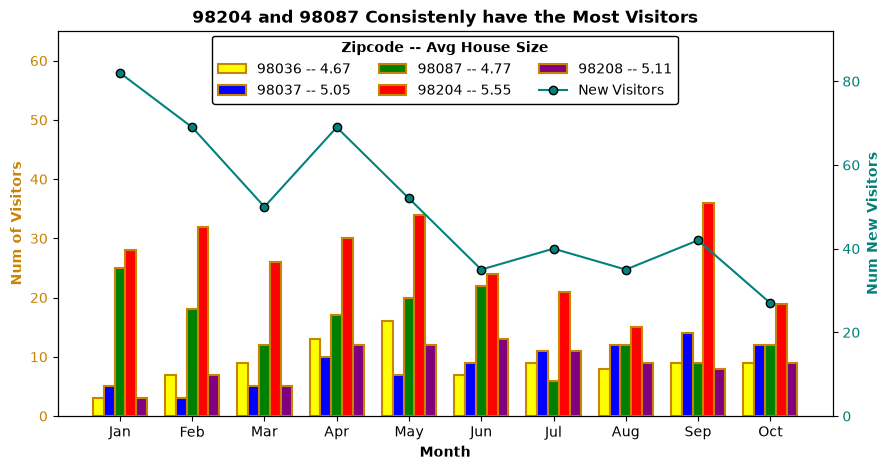

In [28]:
##### Double graph
    # Bar graphs = num of visitors per zipcode
    # Line graph = num of new visitors

##### Line graph data
#### Calculating new visitors per month
num_months = 10
seen = set()
new_visitors = []
for month in range(1,num_months+1):
    df_month = df[df['month'] == month]
    month_visitors = set(
        df_month['full_name'].values.tolist()
    )
    new_visitors.append(
        len(
            month_visitors - seen
        )
    )
    seen.update(
        df[
            df['month'] == month
        ]['full_name'].values.tolist()
    )



##### Bar graph data
#### Avg household size
df_zh = df.groupby(
    by='postal_code',
    as_index=False
).agg(
    avg_house_size = pd.NamedAgg(
        column='number_household_sum',
        aggfunc=lambda series: series.mean().round(2)
    )
)

dict_zip_size = dict(
    zip(
        df_zh['postal_code'].values.tolist(),
        df_zh['avg_house_size'].values.tolist()
    )
)

#### Gathering top X zipcodes
top_X = 5
top_X_zipcodes = df['postal_code']\
    .value_counts()\
    .sort_values(ascending=False)\
    [:top_X].index.to_list()

#### Grouping clients per zipcode
df_clients_per_zip = df.groupby(
    by=['month', 'postal_code'],
    as_index=False
).agg(
    num_clients = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.count()
    )
).sort_values(
    by=['month', 'num_clients'],
    ascending=[True, False]
)

### Ensuring all months have the same zipcodes
all_months =df_clients_per_zip['month'].unique()
all_zips = top_X_zipcodes
full_index = pd.MultiIndex.from_product(
    [all_months, all_zips],
    names=['month','postal_code']
)
df_complete_client_per_zip = df_clients_per_zip\
    .set_index(['month', 'postal_code'])\
    .reindex(full_index, fill_value=0)\
    .reset_index()\
    .sort_values(
        by=['month','num_clients'],
        ascending=[True,False]
    )




#### Visualization
### Pivot table
pivot_df = df_complete_client_per_zip.pivot(index='month', columns='postal_code', values='num_clients')
### Initial configs
center = list(range(-1*int(top_X/2),int(top_X/2),1))\
    if top_X % 2 == 0 else\
    list(range(-1*int(top_X/2),int(top_X/2) + 1,1))
months = pivot_df.index
zipcodes = pivot_df.columns
bar_width = 0.15  # grosor de cada barra
x_positions = np.arange(len(months))
colors = ['yellow', 'blue', 'green', 'red', 'purple']
bars = []
### Bar graph
fig, ax1 = plt.subplots(figsize=(10, 5))
for i, zipcode in enumerate(zipcodes):
    bars.append(ax1.bar(
        x_positions + center[i] * bar_width,  # desplazamiento vertical
        pivot_df[zipcode],
        width=bar_width,
        label=f"{zipcode} -- {dict_zip_size[zipcode]}",
        color=colors[i],
        edgecolor='#c98404',
        linewidth=1.5,
    ))
### Line graph
ax2 = ax1.twinx()
linegraph = ax2.plot(
    x_positions,
    new_visitors,
    label='New Visitors',
    color='#03817B',
    marker='o',
    markeredgecolor='black'
)
### Final configs
## Bargraph
ax1.set_ylim(0,65)
ax1.set_ylabel('Num of Visitors', fontweight='bold', color="#c98404")
ax1.tick_params(axis='y', labelcolor='#c98404')
ax1.set_xticks(x_positions)
ax1.set_xticklabels(MONTHS)
ax1.set_xlabel('Month', fontweight='bold')
## Linegraph
ax2.set_ylabel('Num New Visitors', fontweight='bold', color='#03817B')
ax2.tick_params(axis='y', labelcolor="#03817B")
ax2.set_ylim(0, max(new_visitors)+10)
## Legend
graphs = bars + linegraph
labels= [g.get_label() for g in graphs]
legend = ax1.legend(
    graphs, 
    labels, 
    title='Zipcode -- Avg House Size',
    loc='center',
    bbox_to_anchor = (0.5, 0.9),
    ncols=3,
    framealpha=1,
    edgecolor='black'
)
# legend = ax1.legend(
#     title='Zipcode -- Avg House Size',
#     loc='center',
#     bbox_to_anchor = (0.5, 0.9),
#     ncols=3,
#     framealpha=1,
#     edgecolor='black'
# )
legend.get_title().set_fontweight('bold')
ax1.set_title(
    '98204 and 98087 Consistenly have the Most Visitors',
    fontweight='bold'
)
plt.show()


### Insights
* There is a decrease in new visitors but the number of visitors is consistent, which implies that visitors only come a few times and that frecuent visitors are rare.
* The average household size is approximately the same, yet 98204 has the most visitors, which implies 98204 might have a higher number of families that need supporting
* Considering the ups and downs, there seems to be a seasonal trend

##### Recommendation
* If possible, consider creating a food drive in 98204 and measuring changes in visitors

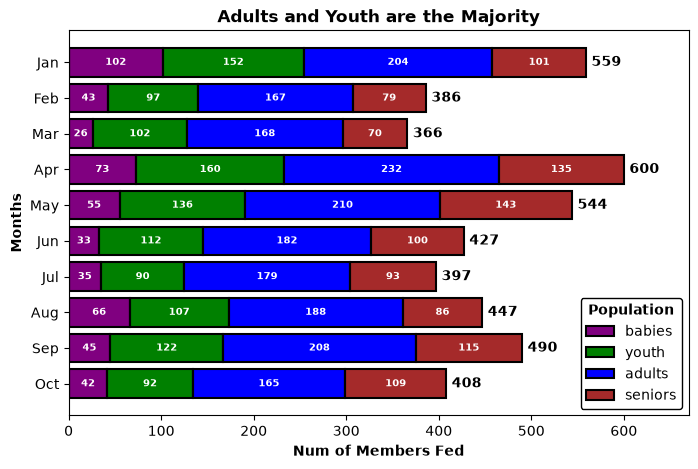

In [29]:
# * Numbers:
#     - Change number of seniors/adults/youth/babies supported throughout time (monthly)
#     - Sum of all numbers
#         * Seeing that change over time as well
##### DF: month and 'numbers_..'
df_month_nums = df.groupby(
    by='month',
    as_index=False
).agg(
    monthly_seniors = pd.NamedAgg(
        column='number_of_seniors',
        aggfunc= lambda series: series.sum()
    ),
    monthly_adults = pd.NamedAgg(
        column='number_of_adults',
        aggfunc=lambda series: series.sum()
    ),
    monthly_youth = pd.NamedAgg(
        column='number_of_youth',
        aggfunc= lambda series: series.sum()
    ),
    monthly_babies = pd.NamedAgg(
        column='number_of_babies',
        aggfunc= lambda series: series.sum()
    ),
    monthly_sum = pd.NamedAgg(
        column='number_household_sum',
        aggfunc= lambda series: series.sum()
    )
).sort_values(
    by='month',
    ascending=True
)

##### Visualization
#### Initial configs
y_pos = np.arange(len(MONTHS))
left_accum = np.zeros(len(MONTHS))
categories = ['monthly_babies', 'monthly_youth', 'monthly_adults', 'monthly_seniors']
category_colors = ['purple', 'green', 'blue', 'brown']
#### Visual Creation
fig, ax = plt.subplots(figsize=(8,5))
for i, cat in enumerate(categories):
    ### Creating horizontal bar graphs
    num_members = df_month_nums[cat].values.tolist()
    bars = ax.barh(
        y_pos,
        num_members,
        left = left_accum,
        color = category_colors[i],
        label = cat.split('_')[1],
        edgecolor='black',
        linewidth=1.5
    )
    ### Creating separtions between inner bars
    altura_barra = 0.7  # ancho de barra por defecto en barh()
    for i in range(len(MONTHS)):
        ax.plot(
            # Line from (x1,y1) to (x2,y2)
            [left_accum[i], left_accum[i]], #[x1, x2]
            [y_pos[i] - altura_barra/2, y_pos[i] + altura_barra/2], #[y1,y2]
            color='black', linewidth=1.5
        )
    ### Creating inner texts
    for bar, valor in zip(bars, num_members):
        x_center = bar.get_x() + bar.get_width() / 2
        y_center = bar.get_y() + bar.get_height() / 2
        ax.text(
            x_center, y_center,
            f"{valor}",  # Texto a mostrar
            ha="center", va="center",
            color="white", fontsize=7, fontweight="bold",
            rotation=90 if valor < 4 else 0
        )
    left_accum += num_members
    ### Creating sum - outer text
ax.bar_label(
    bars,
    labels = [str(v) for v in df_month_nums['monthly_sum'].values],
    label_type='edge',
    fontweight='bold',
    color = 'black',
    padding=4
)

### Configs finales
## Y Axis
ax.set_yticks(range(len(MONTHS)))
ax.set_yticklabels(MONTHS)
ax.set_ylabel('Months', fontweight='bold')
## X Axis
ax.set_xlim(0, max(df_month_nums['monthly_sum'].values) + 70)
ax.set_xlabel('Num of Members Fed', fontweight='bold')
## Show
legend = ax.legend(
    title='Population',
    framealpha=1,
    edgecolor='black'
)
legend.get_title().set_fontweight('bold')
ax.set_title(
    "Adults and Youth are the Majority",
    fontweight='bold'
)
ax.invert_yaxis()
plt.show()

### Insights
* The mayority of people helped are adults and youth
* There seems to be a seasonal trend within each population
* The seniors population makes up a large portion of the data

##### Recommendation
* Try pairing programs for seniors during these food drives

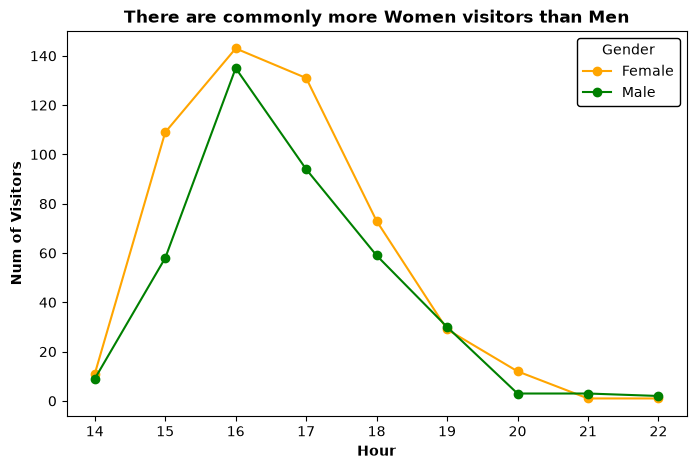

In [30]:
##### Gender - hourly distribution
df_gh = df.groupby(
    by=['gender', 'hour'],
    as_index=False
).agg(
    num_visitors = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.count()
    )
)

#### Dropping outliers
    # Registrations at the following hours occured 1/2 times:
        # 0,1,11,12,13,23
df_gh = df_gh[
    ~df_gh['hour'].isin([0,1,11,12,13,23])
]


#### Visualizacion
### Configuracion inicial
colors = ['orange', 'green']
fig, ax = plt.subplots(figsize=(8,5))
unique_hours = df_gh['hour'].unique().tolist()
genders = ['Female', 'Male']
### Visualizacion
for i, gender in enumerate(genders):
    ax.plot(
        np.arange(len(unique_hours)),
        df_gh[
            df_gh['gender'] == gender
        ]['num_visitors'],
        label = gender,
        color = colors[i],
        marker='o'
    )
### Final configs
ax.set_ylabel('Num of Visitors', fontweight='bold')
ax.set_xticks(np.arange(len(unique_hours)))
ax.set_xticklabels(unique_hours)
ax.set_xlabel('Hour', fontweight='bold')
ax.legend(
    title='Gender',
    framealpha=1,
    edgecolor='black'
)
ax.set_title(
    'There are commonly more Women visitors than Men',
    fontweight='bold'
)

plt.show()

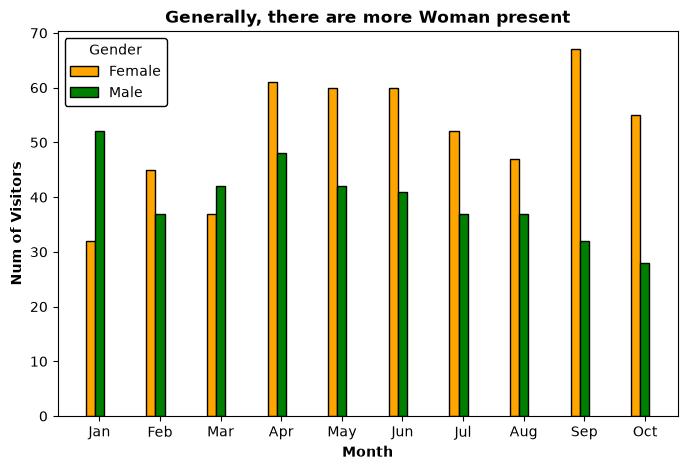

In [31]:
##### Gender - Monthly distribution
df_gh = df.groupby(
    by=['gender', 'month'],
    as_index=False
).agg(
    num_visitors = pd.NamedAgg(
        column='first_name',
        aggfunc= lambda series: series.count()
    )
)


#### Visualizacion
### Configuracion inicial
bar_width = 0.15
colors = ['orange', 'green']
fig, ax = plt.subplots(figsize=(8,5))
unique_months = df_gh['month'].unique().tolist()
genders = ['Female', 'Male']
center = list(range(-1*int(len(genders)/2),int(len(genders)/2),1))\
    if len(genders) % 2 == 0 else\
    list(range(-1*int(len(genders)),int(len(genders)/2) + 1,1))
### Visualizacion
for i, gender in enumerate(genders):
    ax.bar(
        np.arange(len(unique_months)) + center[i]*bar_width,
        df_gh[
            df_gh['gender'] == gender
        ]['num_visitors'],
        width = bar_width,
        label = gender,
        color = colors[i],
        edgecolor='black'
    )
### Final configs
ax.set_ylabel('Num of Visitors', fontweight='bold')
ax.set_xticks(np.arange(len(unique_months)))
ax.set_xticklabels(MONTHS)
ax.set_xlabel('Month', fontweight='bold')
ax.legend(
    title='Gender',
    framealpha=1,
    edgecolor='black'
)
ax.set_title(
    'Generally, there are more Woman present',
    fontweight='bold'
)

plt.show()